In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from typing import Tuple, Dict
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
import matplotlib.dates as mdates
import seaborn as sns

In [2]:
df = pd.read_parquet("../data/processed/clean.parquet")

In [3]:
COLUMNS = ["TotalPrice", "Quantity", "UnitPrice"]

INK = "#1f2933"
MUTED = "#6b7280"
GRID = "#e5e7eb"
BASE = "#4a78b0"
ACCENT = "#e07a2f"

# 2.1 Distribution of key variables

In [4]:
def draw_histogram(log_scale: bool=False):
    fig = plt.figure(figsize=(12, 8))
    grid = fig.add_gridspec(2, 2)

    axes = [
        fig.add_subplot(grid[0, 0]),
        fig.add_subplot(grid[0, 1]),
        fig.add_subplot(grid[1, 0]),
    ]
    plots = [(ax, col, col) for ax, col in zip(axes, COLUMNS)]

    for ax, col, label in plots:
        if not log_scale:
            ax.hist(df[col], bins=60)
        else:
            positive = df[col][df[col] > 0]         
            bins = np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60)
            median = positive.median()

            ax.hist(positive, bins=bins)
            ax.set_xscale("log")
            ax.axvline(median, color="orange", linestyle="--", label=f"Median: {median:.2f}")
            ax.legend()

        ax.set_title(col)
        ax.set_xlabel(label if not log_scale else f"{label} (log scale)")
        ax.set_ylabel("Rows")

    fig.tight_layout()
    plt.show()
        

## Linear scale

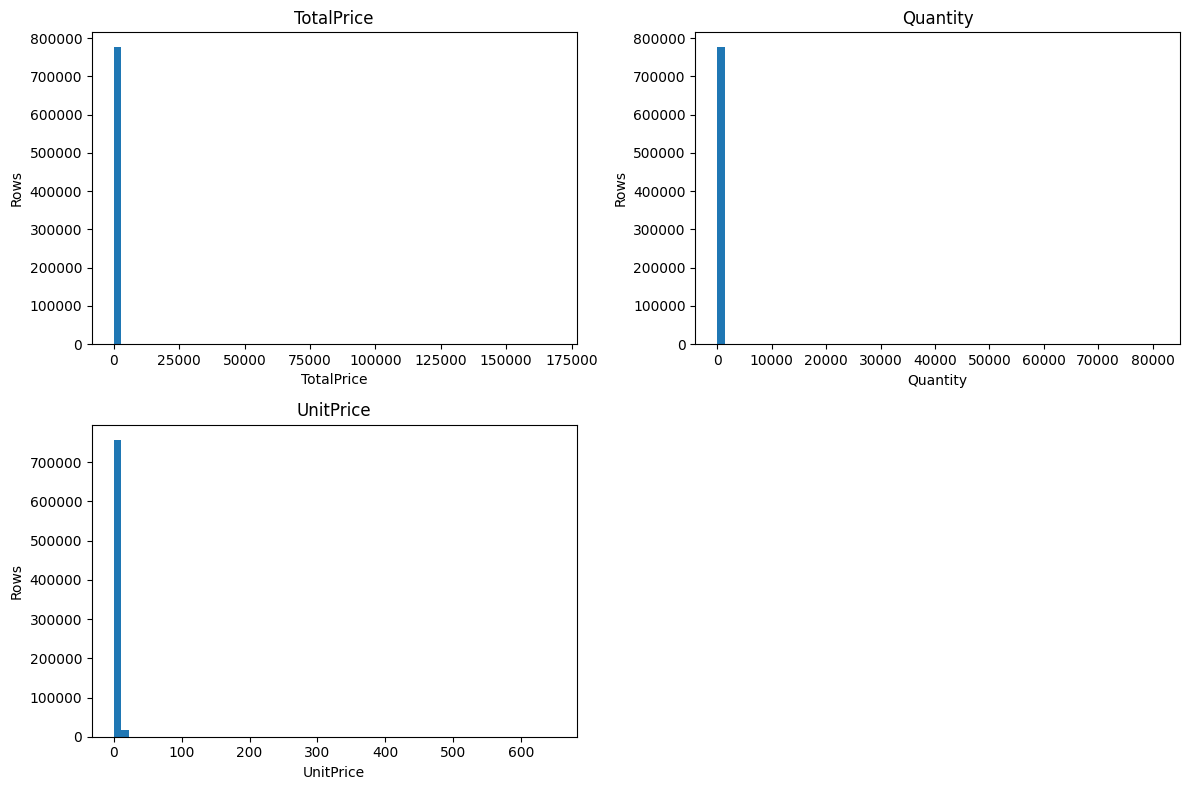

In [5]:
draw_histogram()

## Log scale

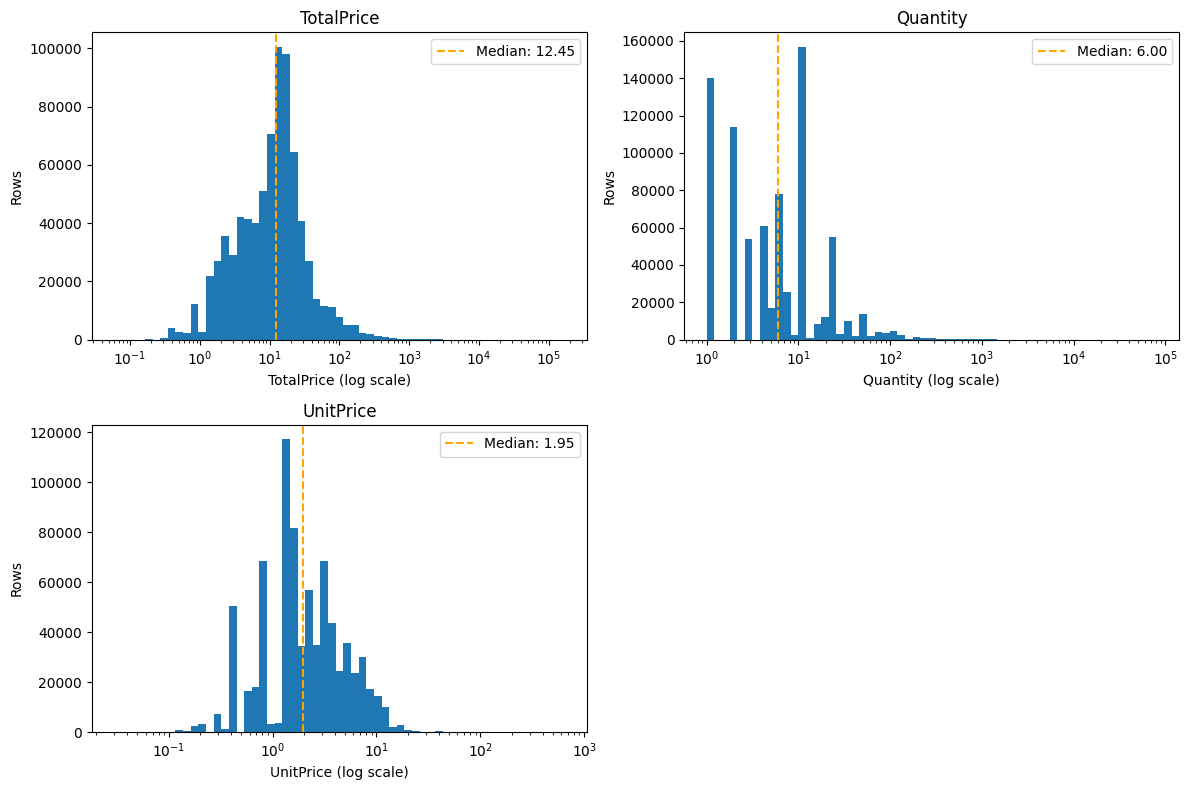

In [6]:
draw_histogram(log_scale=True)

## Outliers

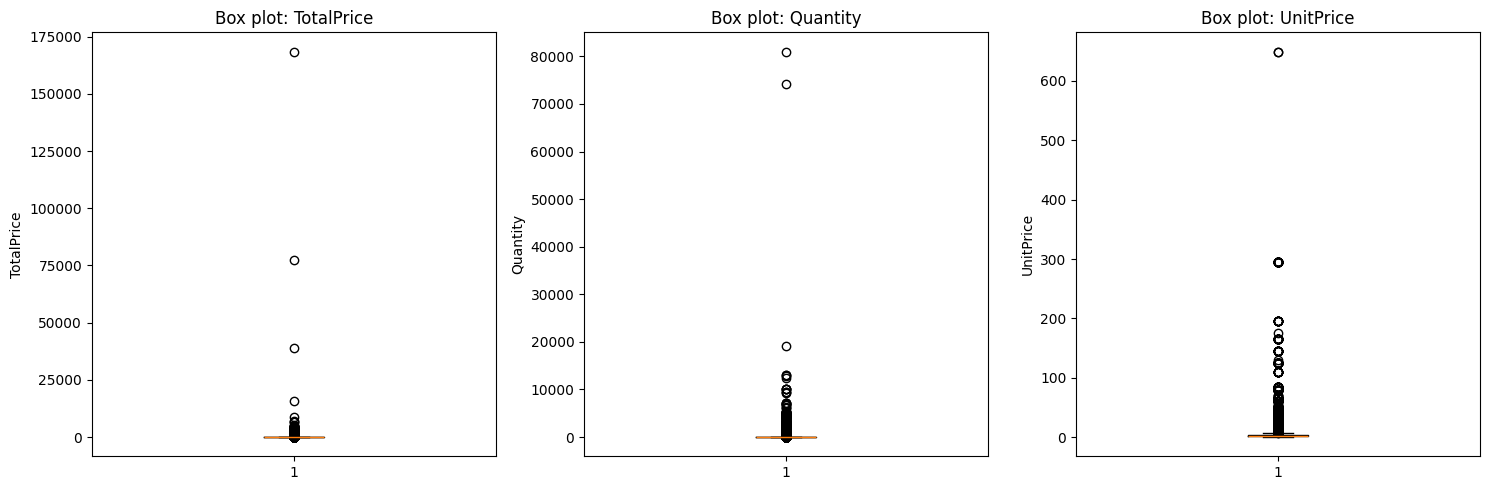

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, col in zip(axes, COLUMNS):
    ax.boxplot(df[col].dropna(), vert=True)
    ax.set_title(f"Box plot: {col}")
    ax.set_ylabel(col)

plt.tight_layout()
plt.show()

In [8]:
def iqr_outliers(series: pd.Series) -> Tuple:
    s = series.dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (s < lower) | (s > upper)
    
    return lower, upper, mask.sum(), round(mask.mean() * 100, 2)

results = []
for col in COLUMNS:
    lower, upper, num_outlier, percentage = iqr_outliers(df[col])
    results.append({
        "Column": col,
        "Lower Bound": lower,
        "Upper Bound": upper,
        "Number Outliers": num_outlier,
        "Percentage": percentage
    })

df_results = pd.DataFrame(results)
df_results

,Column,Lower Bound,Upper Bound,Number Outliers,Percentage
0,TotalPrice,-17.325,42.075,62197,8.01
1,Quantity,-13.000,27.000,51077,6.58
2,UnitPrice,-2.500,7.500,63131,8.13


## Quantity, UnitPirce, TotalPrice median and mean

In [9]:
def get_mean_median(column: str) -> Dict:
    mean = round(df[column].mean(), 2)
    median = round(df[column].median(), 2)

    return {
        "Column": column,
        "Mean": mean,
        "Median": median
    }

mean_median = [
    get_mean_median("Quantity"),
    get_mean_median("UnitPrice"),
    get_mean_median("TotalPrice"),
]

df_mean_median = pd.DataFrame(mean_median)
df_mean_median

,Column,Mean,Median
0,Quantity,13.52,6.00
1,UnitPrice,2.93,1.95
2,TotalPrice,21.98,12.45


# 2.2. Top10 TotalPrice items

In [10]:
df.nlargest(10, "TotalPrice")

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,List,TotalPrice,Year,Month,Date,DayOfWeek,Hour
776118,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446,United Kingdom,Year 2010-2011,168469.60,2011,2011-12,2011-12-09,4,9
421804,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346,United Kingdom,Year 2010-2011,77183.60,2011,2011-01,2011-01-18,1,10
538378,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.50,15098,United Kingdom,Year 2010-2011,38970.00,2011,2011-06,2011-06-10,4,15
332011,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,2010-11-04 11:36:00,1.69,15838,United Kingdom,Year 2009-2010,15818.40,2010,2010-11,2010-11-04,3,11
169271,511465,15044A,PINK PAPER PARASOL,3500,2010-06-08 12:59:00,2.55,18008,United Kingdom,Year 2009-2010,8925.00,2010,2010-06,2010-06-08,1,12
630484,567423,23243,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,2011-09-20 11:05:00,5.06,17450,United Kingdom,Year 2010-2011,7144.72,2011,2011-09,2011-09-20,1,11
417500,540815,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-01-11 12:55:00,2.10,15749,United Kingdom,Year 2010-2011,6539.40,2011,2011-01,2011-01-11,1,12
493189,550461,21108,FAIRY CAKE FLANNEL ASSORTED COLOUR,3114,2011-04-18 13:20:00,2.10,15749,United Kingdom,Year 2010-2011,6539.40,2011,2011-04,2011-04-18,0,13
289757,525968,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,3120,2010-10-08 10:10:00,1.66,15838,United Kingdom,Year 2009-2010,5179.20,2010,2010-10,2010-10-08,4,10
688829,573003,23084,RABBIT NIGHT LIGHT,2400,2011-10-27 12:11:00,2.08,14646,Netherlands,Year 2010-2011,4992.00,2011,2011-10,2011-10-27,3,12


# 2.3 Sale by Countries

In [11]:
by_countries = (df.groupby("Country")
                .agg(Revenue=("TotalPrice", "sum"),
                     Customers=("CustomerID", "nunique"),
                     Invoices=("InvoiceNo", "nunique"))
                .sort_values("Revenue", ascending=False))

by_countries["Share %"] = by_countries["Revenue"] / by_countries["Revenue"].sum() * 100
by_countries["AverageCart"] = by_countries["Revenue"] / by_countries["Invoices"]
by_countries

,Revenue,Customers,Invoices,Share %,AverageCart
Country,,,,,
United Kingdom,14288773.50,5334,33361,83.713884,428.307710
EIRE,586626.08,3,528,3.436876,1111.034242
Netherlands,549773.41,22,216,3.220967,2545.247269
Germany,383289.00,107,753,2.245582,509.015936
France,309403.16,93,590,1.812706,524.412136
Australia,167800.01,15,89,0.983093,1885.393371
Spain,97766.75,38,144,0.572788,678.935764
Switzerland,93400.94,22,82,0.547210,1139.035854
Sweden,86045.14,19,98,0.504114,878.011633


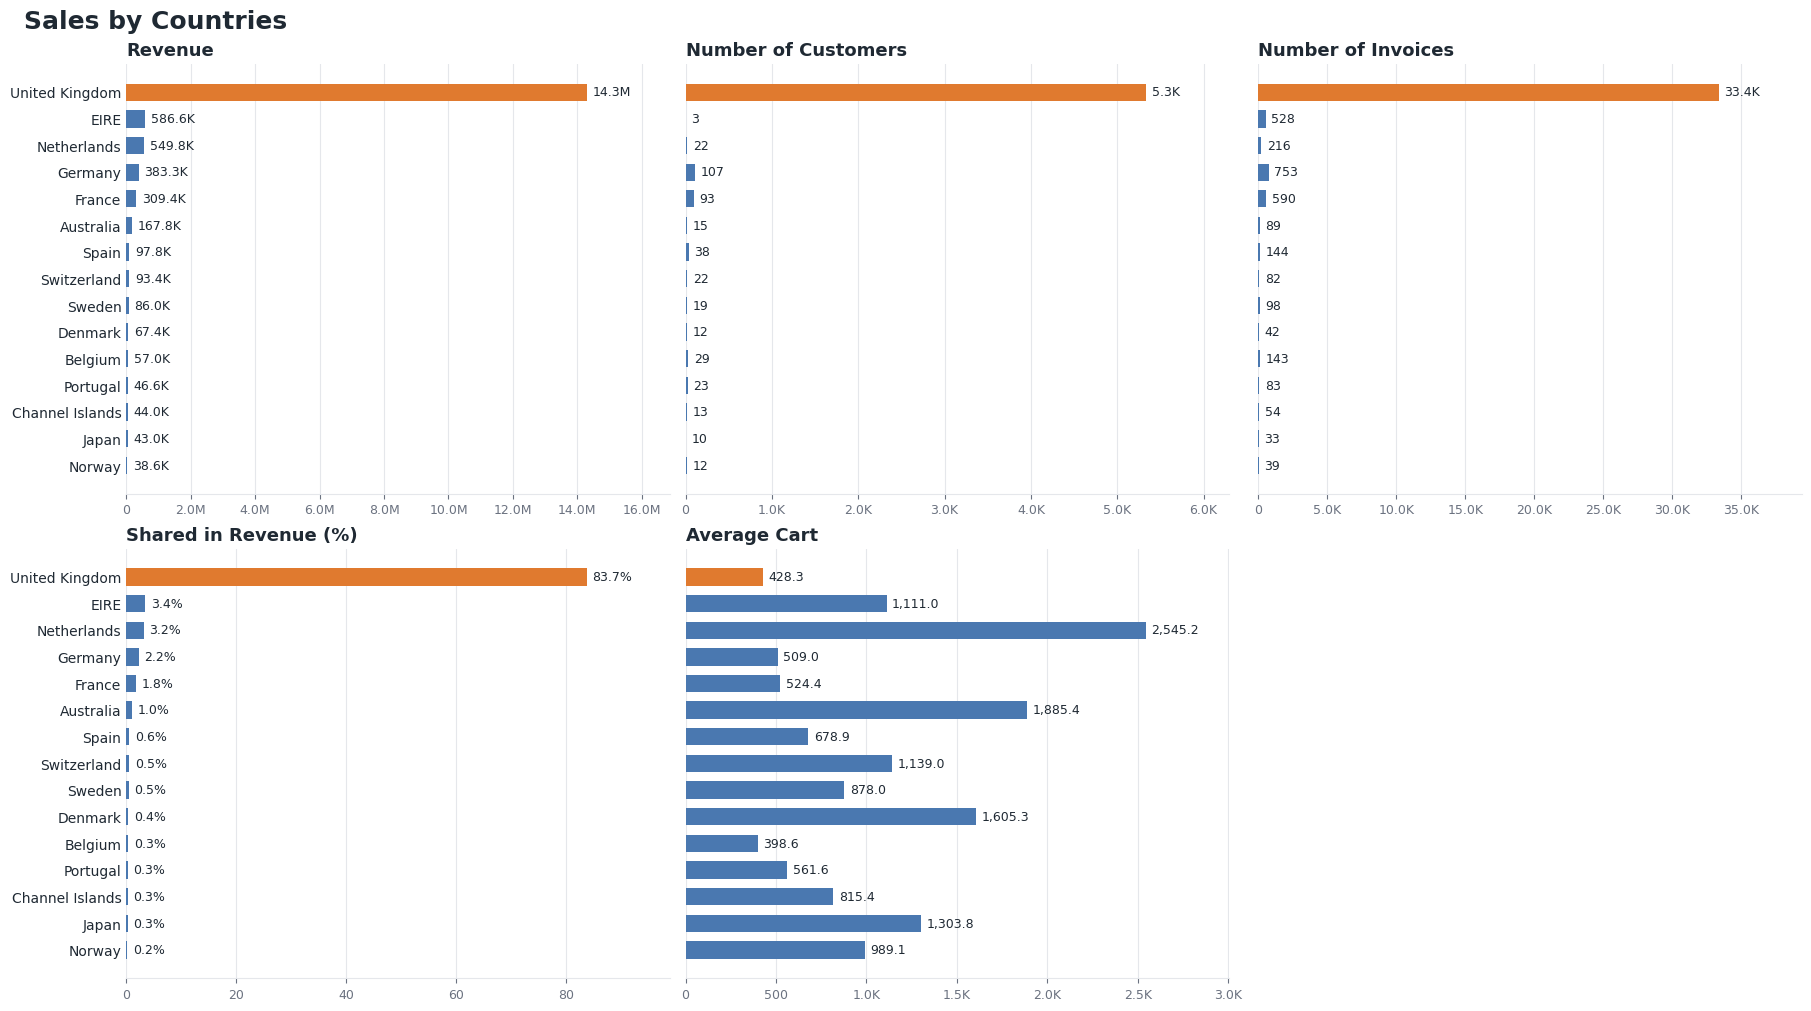

In [12]:
def compact(v: int) -> str:
    for bound, suffix in ((1e6, "M"), (1e3, "K")):
        if abs(v) >= bound:
            return f"{v / bound:,.1f}{suffix}"
    return f"{v:,.0f}"


def draw_by_countries(data: pd.DataFrame, title: str, n: int=15, highlight: str="United Kingdom"):
    d = data.copy()
    d["Shared %"] = d["Revenue"] / d["Revenue"].sum() * 100
    d = d.sort_values("Revenue", ascending=False).head(n)

    metrics = [
        ("Revenue", "Revenue", compact),
        ("Customers", "Number of Customers", compact),
        ("Invoices", "Number of Invoices", compact),
        ("Shared %", "Shared in Revenue (%)", lambda v: f"{v:.1f}%"),
        ("AverageCart", "Average Cart", lambda v: f"{v:,.1f}"),
    ]

    colors = [ACCENT if z == highlight else BASE for z in d.index]
    y = np.arange(len(d))

    fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharey=True, constrained_layout=True)
    axes = axes.ravel()

    for ax, (col, t, fmt) in zip(axes, metrics):
        bars = ax.barh(y, d[col], color=colors, height=0.65)
        ax.bar_label(bars, labels=[fmt(v) for v in d[col]], padding=4, fontsize=9, color=INK)

        ax.set_title(t, loc="left", fontsize=13, fontweight="bold", color=INK)
        ax.margins(x=0.18)
        ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: compact(v)))
        ax.tick_params(axis="x", colors=MUTED, labelsize=9)
        ax.tick_params(axis="y", length=0, labelsize=10, labelcolor=INK)
        ax.set_axisbelow(True)
        ax.xaxis.grid(True, color=GRID, linewidth=0.8)
        for side in ("top", "right", "left"):
            ax.spines[side].set_visible(False)
        ax.spines["bottom"].set_color(GRID)

    axes[0].set_yticks(y, d.index)
    axes[0].invert_yaxis() 
    axes[-1].axis("off")

    fig.suptitle(title, fontsize=18, fontweight="bold", color=INK, x=0.01, ha="left")
    plt.show()

draw_by_countries(by_countries, "Sales by Countries")

# 2.4 Sales over Time

## Monthly

In [13]:
monthly = df.groupby("Month")["TotalPrice"].sum().reset_index()
monthly["Date"] = pd.to_datetime(monthly["Month"])

monthly.tail(4)

,Month,TotalPrice,Date
21,2011-09,938752.63,2011-09-01
22,2011-10,1002326.56,2011-10-01
23,2011-11,1136534.00,2011-11-01
24,2011-12,512228.08,2011-12-01


In [14]:
print(f"Last date: {df['InvoiceDate'].max()}")

Last date: 2011-12-09 12:50:00


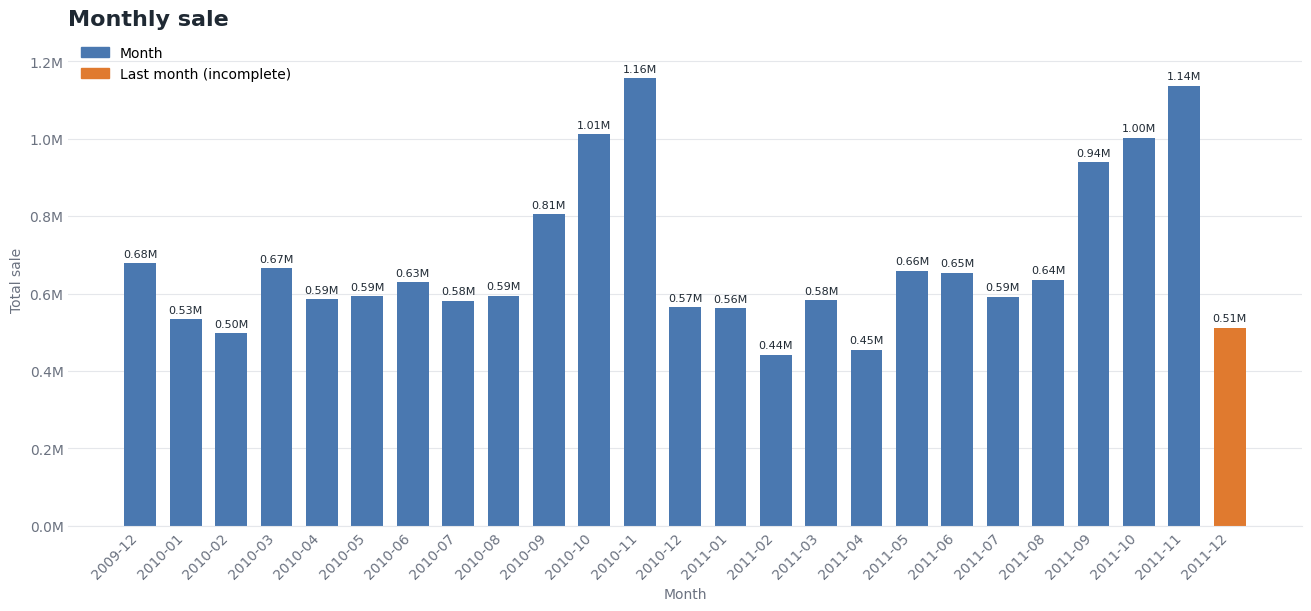

In [15]:
monthly = monthly.sort_values("Date")
last_month = monthly["Date"].max()

colors = [ACCENT if d == last_month else BASE for d in monthly["Date"]]
months = monthly["Date"].dt.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)

bars = ax.bar(months, monthly["TotalPrice"], color=colors, width=0.7)
ax.bar_label(
    bars,
    labels=[f"{v / 1e6:.2f}M" for v in monthly["TotalPrice"]],
    padding=3,
    fontsize=8,
    color=INK
)

ax.set_title("Monthly sale", loc="left", fontsize=16, fontweight="bold", color=INK)
ax.set_xlabel("Month", color=MUTED)
ax.set_ylabel("Total sale", color=MUTED)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e6:.1f}M"))
ax.margins(y=0.1)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.tick_params(colors=MUTED, length=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, color=GRID, linewidth=0.8)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

ax.legend(
    handles=[
        Patch(color=BASE, label="Month"),
        Patch(color=ACCENT, label="Last month (incomplete)")
        ],
    frameon=False, loc="upper left"
)

plt.show()

In [16]:
complete_months = monthly.iloc[:-1]  

best = complete_months.loc[complete_months["TotalPrice"].idxmax()]
worst  = complete_months.loc[complete_months["TotalPrice"].idxmin()]

best_month, worst_month = best["Month"], worst["Month"]
best_total, worst_total = best["TotalPrice"], worst["TotalPrice"]

print(f"Best: {best_month} = {best_total:,.0f}")
print(f"Worst : {worst_month} = {worst_total:,.0f}")

Best: 2010-11 = 1,155,978
Worst : 2011-02 = 442,294


## Daily

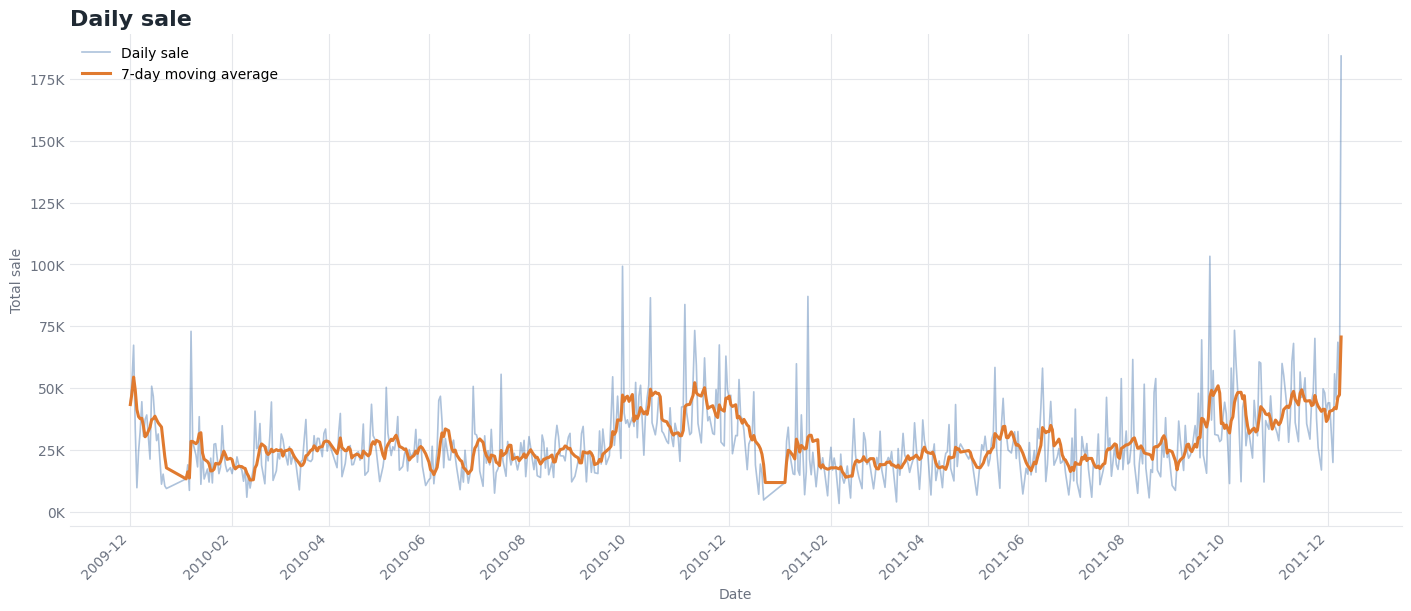

In [17]:
daily = df.groupby("Date")["TotalPrice"].sum().reset_index()
daily["Date"] = pd.to_datetime(daily["Date"])
daily = daily.sort_values("Date").set_index("Date")
daily["MA7"] = daily["TotalPrice"].rolling("7D").mean()

fig, ax = plt.subplots(figsize=(14, 6), constrained_layout=True)

ax.plot(
    daily.index,
    daily["TotalPrice"],
    color=BASE,
    alpha=0.45,
    linewidth=1.2,
    label="Daily sale"
)
ax.plot(
    daily.index,
    daily["MA7"],
    color=ACCENT,
    linewidth=2.2,
    label="7-day moving average"
)

ax.set_title(
    "Daily sale",
    loc="left",
    fontsize=16,
    fontweight="bold", 
    color=INK
)
ax.set_xlabel("Date", color=MUTED)
ax.set_ylabel("Total sale", color=MUTED)

ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}K"))
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

ax.tick_params(colors=MUTED, length=0)
ax.set_axisbelow(True)
ax.grid(True, color=GRID, linewidth=0.8)

for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)

ax.legend(frameon=False, loc="upper left")
plt.show()

# 2.5 When customers buy

In [18]:
heat = df.pivot_table(
    index="DayOfWeek",
    columns="Hour",
    values="TotalPrice",
    aggfunc="sum"
)
heat

Hour,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
DayOfWeek,,,,,,,,,,,,,,,
0,NaN,15830.42,88656.82,237882.96,345353.46,330976.96,394910.11,425491.50,327530.18,271870.48,200882.52,64281.70,6561.17,NaN,NaN
1,NaN,11442.26,116586.28,291386.70,493337.31,462704.20,468622.38,424520.49,329702.71,327203.86,205790.85,90813.47,25539.01,14623.87,661.80
2,NaN,10110.76,86149.66,245480.19,449604.98,375196.99,527200.62,418585.11,353035.69,268166.46,177454.05,53796.67,NaN,2893.40,13031.50
3,4.25,15991.41,120349.59,270024.13,450255.33,384592.49,510144.78,386059.38,382707.28,420746.89,247199.23,211473.35,157479.14,105827.29,24956.21
4,NaN,21654.72,106820.20,410011.21,376802.85,318963.26,412261.04,313021.33,293309.34,238901.64,111970.70,54957.16,75.50,373.04,19.19
5,NaN,NaN,NaN,NaN,1059.74,230.20,2110.65,2520.49,1130.93,1599.74,1151.30,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,2853.12,172634.77,310890.43,344772.16,334907.93,236884.34,275958.49,79056.95,NaN,NaN,NaN,NaN


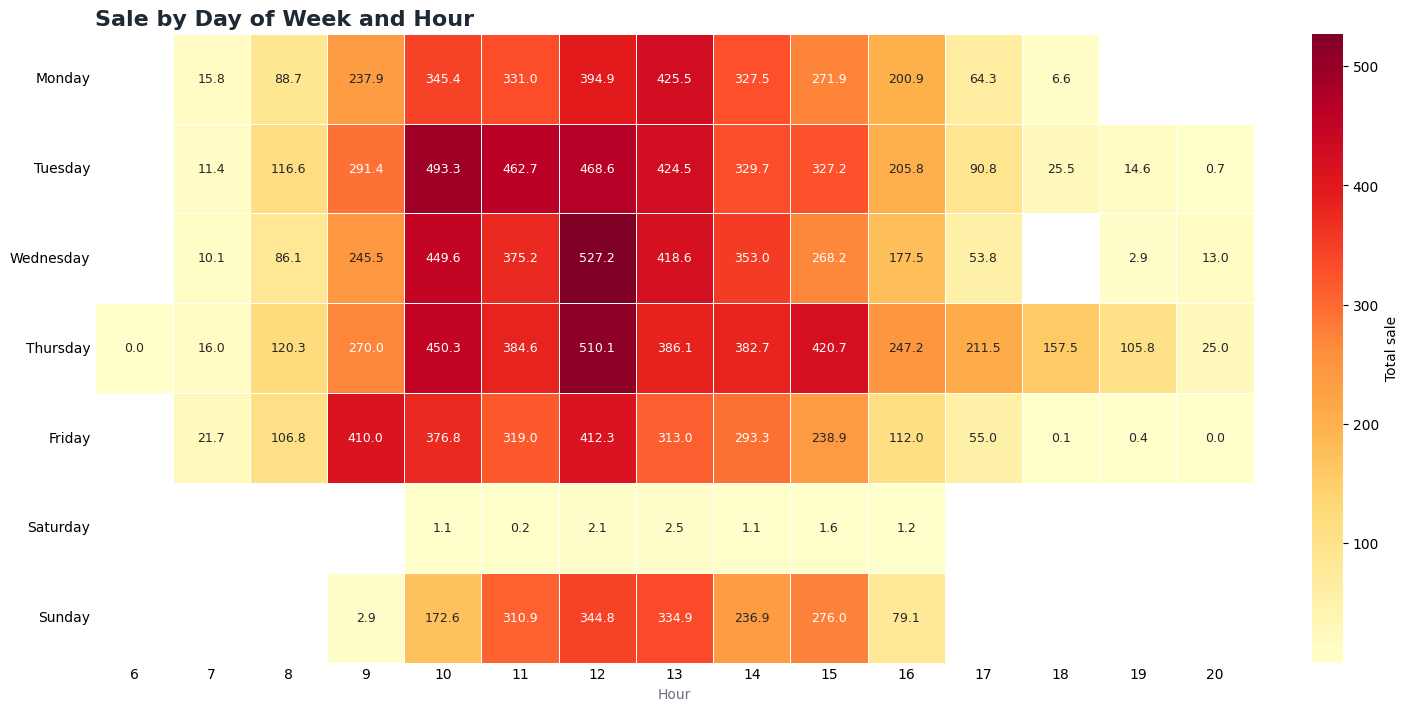

In [19]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

heat = df.pivot_table(
    index="DayOfWeek",
    columns="Hour",
    values="TotalPrice",
    aggfunc="sum"
).reindex(range(7))       
heat.index = days          
heat_k = heat / 1000        

fig, ax = plt.subplots(figsize=(14, 7), constrained_layout=True)

sns.heatmap(
    heat_k,
    ax=ax,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    annot_kws={"fontsize": 9},
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "Total sale"}
)
ax.set_title(
    "Sale by Day of Week and Hour", 
    loc="left",
    fontsize=16, 
    fontweight="bold", 
    color=INK
)
ax.set_xlabel("Hour", color=MUTED)
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0, length=0)
ax.tick_params(axis="x", length=0)

plt.show()

In [20]:
day_sales = (
    df.groupby("DayOfWeek")["TotalPrice"].sum()
      .rename("Sale")
      .reset_index()
)
day_sales.columns

day_sales["Day"] = day_sales["DayOfWeek"].map(dict(enumerate(days)))
day_sales["Shared (%)"] = day_sales["Sale"] / day_sales["Sale"].sum() * 100

day_sales = (
    day_sales[["Day", "Sale", "Shared (%)"]]
    .sort_values("Sale", ascending=False)
    .reset_index(drop=True)
)

day_sales

,Day,Sale,Shared (%)
0,Thursday,3687810.75,21.605840
1,Tuesday,3262935.19,19.116615
2,Wednesday,2980706.08,17.463114
3,Monday,2710228.28,15.878461
4,Friday,2659141.18,15.579156
5,Sunday,1757958.19,10.299380
6,Saturday,9803.05,0.057433
